# Generating drift

**Drift** is a systematic shift of the data distribution: the same data-generating process starts producing values that are translated (or scaled) compared to the values observed before.

This notebook shows the **two levers** available in badgers to inject drift, in increasing complexity:

1. **Acting on the observation process** — directly translate the observed values of one or several columns (this can represent a change in the measurement process, a systematic bias in a sensor, etc.). No causal model is involved; these generators *do not use a DGP* and do not propagate anything: the change is exactly the shift requested. badgers offers them in two flavors:
   - **deterministic** (`FixedShiftGenerator`, `FixedShiftClassesGenerator`): every affected value is translated by *exactly* the requested amount, in a fully reproducible way;
   - **random** (`RandomShiftGenerator`, `RandomShiftClassesGenerator`): the shift magnitude is *drawn* from a normal distribution whose standard deviation is the requested amount.
2. **Acting on the data-generating process (DGP)** — perturb a node of a *fitted causal model* and let the shift **propagate** to the descendants through the structural equations (`CausalDriftGenerator`).

All of them accept a **selector** to decide which rows are affected (see the *Understanding badgers* notebook for the selector contract).

## Goal

Translate the data distribution: deterministic fixed shifts first, then random shifts with signed per-column magnitudes, then per-class drift on a causal graph.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import default_rng
from sklearn.datasets import make_blobs

from badgers.generators.tabular_data.drift import (
    FixedShiftGenerator, FixedShiftClassesGenerator,
    RandomShiftGenerator, RandomShiftClassesGenerator,
)

rng = default_rng(seed=0)

In [2]:
X, y = make_blobs(centers=4, random_state=0)
# classes are a column of X
Xc = np.column_stack([X, y])
column_mapping = {'f0': 0, 'f1': 1, 'cls': 2}
cls = Xc[:, column_mapping['cls']]   # explicit class vector for plotting
print(X.shape, '->', Xc.shape)

(100, 2) -> (100, 3)


## Part A — Acting on the observation process (no DGP)

**What these generators do:** they standardize `X` (each column to mean
0, variance 1), add the shift, and un-standardize. The result is a
translation of the observed values only — no causal structure is used,
and nothing propagates beyond the shifted columns.

### Deterministic: translate all rows (`FixedShiftGenerator`)

Every value of the selected columns is translated by **exactly**
`shift_std` standard deviations (the parameter may be a scalar or a
signed per-column array). No random number is drawn, so the same input
always produces the same output — useful for controlled, reproducible
benchmark scenarios.

In [3]:
gen = FixedShiftGenerator()
Xt = gen.generate(X=X.copy(), shift_std=np.array([2., -2.]))
# verify: the shift is EXACTLY shift_std sigma units per column
delta = Xt - X
assert np.allclose(delta, np.array([2., -2.]) * X.std(axis=0, ddof=0))

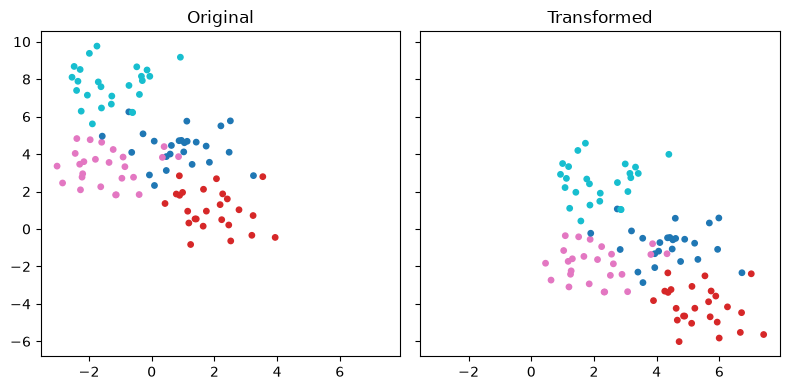

In [4]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
axes[0].scatter(X[:, 0], X[:, 1], c=y, cmap='tab10', s=15)
axes[1].scatter(Xt[:, 0], Xt[:, 1], c=y, cmap='tab10', s=15)
axes[0].set_title('Original')
axes[1].set_title('Transformed')
plt.tight_layout()

### Deterministic: translate per class (`FixedShiftClassesGenerator`)

The class values are read from a column of `X` (here the last column,
`cls`). A `ClassSelector` builds one boolean mask per class value: each
class gets its own shift — here given as a dict `{class_value: shift}`.
Classes not present in the dict are left untouched.

Note: the **class column is never shifted** (it defines *which* rows
are affected, so modifying it would corrupt the selection). Pass
`class_column=` (int position or column name) to make it explicit, or
`variables=` to restrict/override the columns that get shifted.

In [5]:
from badgers.core.selectors import ClassSelector

column_mapping = {"f0": 0, "f1": 1, "cls": 2}
selector = ClassSelector("cls", column_mapping, {"cls": {0: 1., 1: 1., 2: 1., 3: 1.}}, rng=rng)

gen = FixedShiftClassesGenerator()
Xt = gen.generate(X=Xc.copy(), selector=selector,
                  shift={0: 4.0, 1: 2.0, 2: 4.0, 3: 0.0})

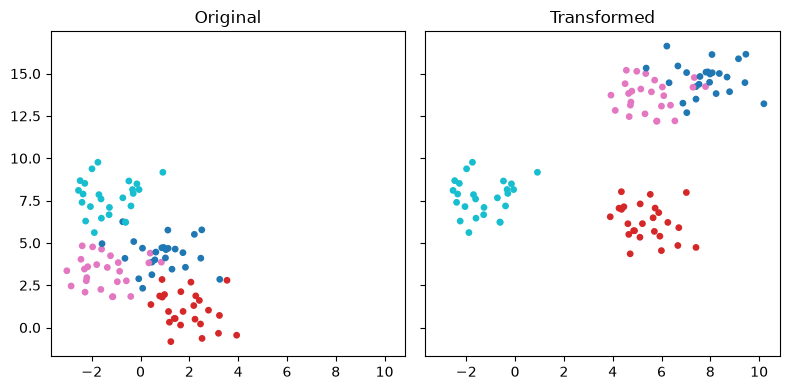

In [6]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
axes[0].scatter(Xc[:, 0], Xc[:, 1], c=cls, cmap='tab10', s=15)
axes[1].scatter(Xt[:, 0], Xt[:, 1], c=Xt[:, 2], cmap='tab10', s=15)
axes[0].set_title('Original')
axes[1].set_title('Transformed')
plt.tight_layout()

### Random: translate all rows (`RandomShiftGenerator`)

Same contract as the deterministic version, but the shift actually
applied is **drawn** from a normal distribution: for each column the
draw is `N(0, shift_std) * sign(shift_std)` — the absolute value of
`shift_std` sets the scale, its sign sets the direction. With a scalar
`shift_std` all columns get independent draws of the same scale.

In [7]:
gen = RandomShiftGenerator(random_generator=rng)
Xt = gen.generate(X=X.copy(), shift_std=np.array([2., -2.]))

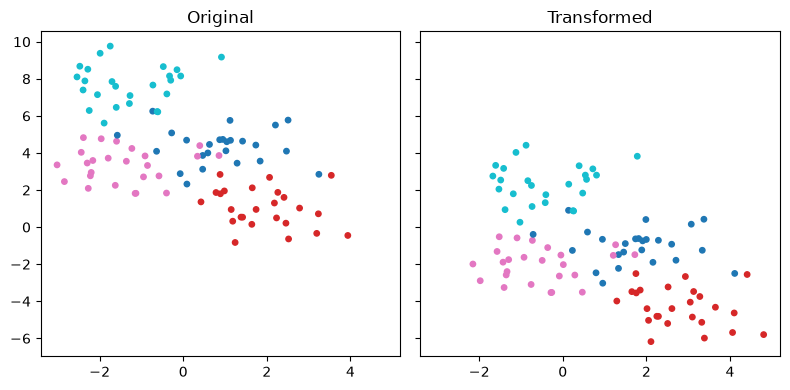

In [8]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
axes[0].scatter(X[:, 0], X[:, 1], c=y, cmap='tab10', s=15)
axes[1].scatter(Xt[:, 0], Xt[:, 1], c=y, cmap='tab10', s=15)
axes[0].set_title('Original')
axes[1].set_title('Transformed')
plt.tight_layout()

### Random: translate per class (`RandomShiftClassesGenerator`)

Each class gets its own independent shift *draw*. `shift_std` may be a
scalar (same scale for every class) or a dict `{class_value: std}`.

In [9]:
from badgers.core.selectors import ClassSelector

column_mapping = {"f0": 0, "f1": 1, "cls": 2}
selector = ClassSelector("cls", column_mapping, {"cls": {0: 1., 1: 1., 2: 1., 3: 1.}}, rng=rng)

gen = RandomShiftClassesGenerator(random_generator=rng)
Xt = gen.generate(X=Xc.copy(), selector=selector, shift_std=2.0)

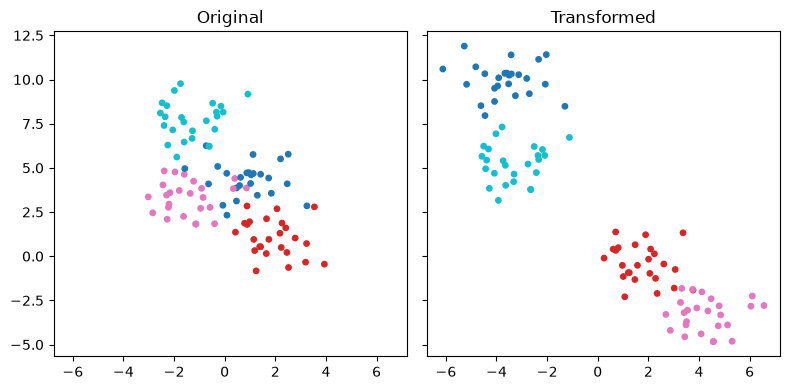

In [10]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
axes[0].scatter(Xc[:, 0], Xc[:, 1], c=cls, cmap='tab10', s=15)
axes[1].scatter(Xt[:, 0], Xt[:, 1], c=Xt[:, 2], cmap='tab10', s=15)
axes[0].set_title('Original')
axes[1].set_title('Transformed')
plt.tight_layout()

In [11]:
# per-class shift magnitude: one value per class (isotropic per class)
gen = RandomShiftClassesGenerator(random_generator=rng)
Xt = gen.generate(X=Xc.copy(), selector=selector,
                  shift_std={0: 4.0, 1: 2.0, 2: 4.0, 3: 0.0})

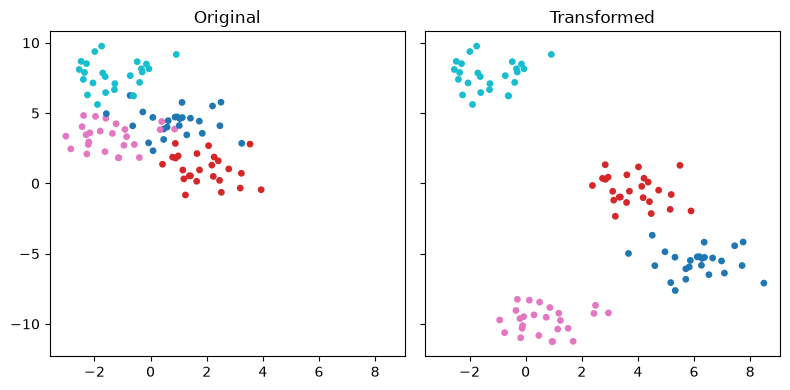

In [12]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
axes[0].scatter(Xc[:, 0], Xc[:, 1], c=cls, cmap='tab10', s=15)
axes[1].scatter(Xt[:, 0], Xt[:, 1], c=Xt[:, 2], cmap='tab10', s=15)
axes[0].set_title('Original')
axes[1].set_title('Transformed')
plt.tight_layout()

### What `shift_std` / `drift_std` actually mean

Both parameters express the shift **in units of the column's standard
deviation** (`sigma`). Internally every drift generator does:

```
z = (X - mean) / std          # normalize: each column has sigma = 1
z += shift                    # deterministic: shift = shift_std
                              # random: shift ~ N(0, shift_std * sigma)
X' = z * std + mean           # un-normalize
```

So `shift_std = 2` on column `f0` means exactly: *"move column `f0` by
2 of its own standard deviations"* — a column with a wide range gets a
proportionally larger absolute shift than a narrow one. The shift is a
single value per column, applied to **all** affected rows (that is what
makes it *drift* and not *noise* — noise redraws per row). The
deterministic generators apply it verbatim; the random ones draw it
once.

In [13]:
# verify the semantics: the shift DRAWN for f0, expressed in sigma units,
# equals a draw from N(0, shift_std) -- i.e. shift_std sets the scale of the
# shift in standard deviations, it is not the shift itself.
X_test = X[:, :2].astype(float).copy()
gen = RandomShiftGenerator(random_generator=default_rng(42))
Xt_test = gen.generate(X_test, shift_std=np.array([2.0, 0.0]))

sigma0 = X_test[:, 0].std()                 # sigma of the ORIGINAL column
observed_z = (Xt_test[:, 0] - X_test[:, 0]).mean() / sigma0
expected_z = default_rng(42).normal(0., 2.0, size=2)[0]  # the same draw
print(f'shift of f0 in sigma units: {observed_z:.4f}')
print(f'draw from N(0, shift_std=2):  {expected_z:.4f}')
print('match:', np.isclose(observed_z, expected_z))
print('f1 untouched:', np.allclose(Xt_test[:, 1], X_test[:, 1]))

shift of f0 in sigma units: 0.6094
draw from N(0, shift_std=2):  0.6094
match: True
f1 untouched: True


## Part B — Acting on the data-generating process (DGP)

**What the generator does:** `CausalDriftGenerator` takes a *fitted
DGP* (a causal model of the data). It shifts a node of choice,
then **re-evaluates the structural equations of the descendants** on
the shifted rows (Pearl surgery): the change propagates exactly as it
would in the real system. Only downstream nodes are affected; upstream
nodes and untouched rows stay as they were.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

import dowhy.gcm as gcm
from badgers.core.dgp.backends import GcmSCMDGP
from badgers.generators.tabular_data.drift.causal import CausalDriftGenerator


def make_scm(graph):
    scm = gcm.StructuralCausalModel(graph)
    for node in graph.nodes:
        if not list(graph.predecessors(node)):
            scm.set_causal_mechanism(node, gcm.EmpiricalDistribution())
        else:
            scm.set_causal_mechanism(node, gcm.AdditiveNoiseModel(
                prediction_model=gcm.ml.create_linear_regressor()))
    return scm


C:\Users\siebert\PycharmProjects\badgers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [15]:
from _shared import generate_linear_data, draw_graph, plot_2panel  # from docs/tutorials/tabular-data/_shared.py

### 1. Build the causal graph

We use a three-node chain `X -> Y -> Z`. The node names are symbolic;
a `column_mapping` maps them to column positions of `X`.


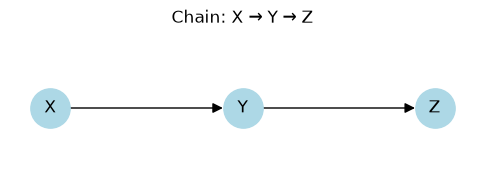

In [16]:
# --- Build the chain X -> Y -> Z ---
chain = nx.DiGraph()
chain.add_edges_from([("X", "Y"), ("Y", "Z")])

draw_graph(chain, title="Chain: X → Y → Z")
plt.show()


### 2. Generate data from the DAG

Each node is a weighted sum of its parents plus noise, so the data
already carries the causal structure the generator will exploit.


In [17]:
# Part B: a fresh RNG stream (independent of Part A)
rng = np.random.default_rng(42)

X, column_mapping = generate_linear_data(
    chain, n_samples=100, rng=rng,
    coefficients={("X", "Y"): 2.0, ("Y", "Z"): 0.5},
)
print(f"X shape: {X.shape}")
print(f"column_mapping: {column_mapping}")


X shape: (100, 3)
column_mapping: {'X': 0, 'Y': 1, 'Z': 2}


array([[<Axes: xlabel='X', ylabel='X'>, <Axes: xlabel='Y', ylabel='X'>,
        <Axes: xlabel='Z', ylabel='X'>],
       [<Axes: xlabel='X', ylabel='Y'>, <Axes: xlabel='Y', ylabel='Y'>,
        <Axes: xlabel='Z', ylabel='Y'>],
       [<Axes: xlabel='X', ylabel='Z'>, <Axes: xlabel='Y', ylabel='Z'>,
        <Axes: xlabel='Z', ylabel='Z'>]], dtype=object)

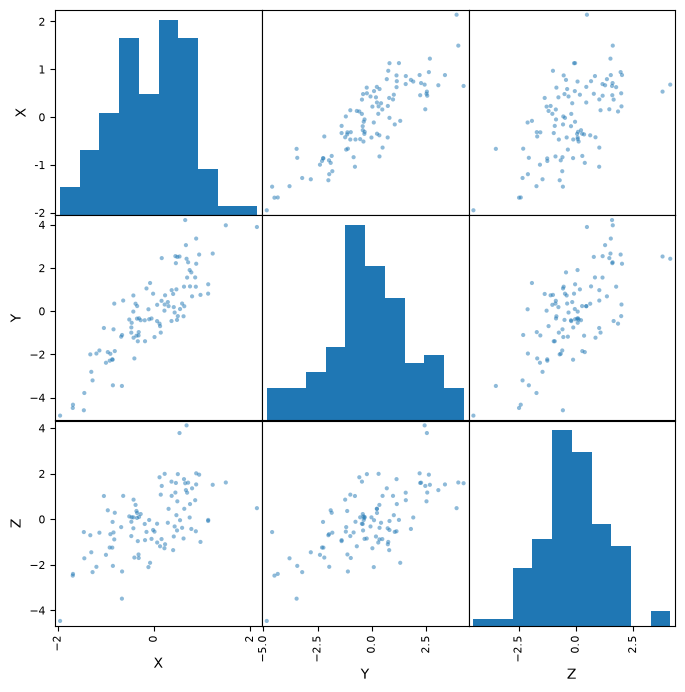

In [18]:
pd.plotting.scatter_matrix(pd.DataFrame(X, columns=column_mapping.keys()), figsize=(8, 8), diagonal='hist')

### 3. Fit the DGP

The `GcmSCMDGP` adapter wraps a `dowhy.gcm.StructuralCausalModel`:
every non-root node's mechanism is a linear `AdditiveNoiseModel` fitted
on the *original* data, root nodes resample the observed values. The
SCM is built with dowhy-gcm's own API (see the `make_scm` helper).

In [19]:
dgp = GcmSCMDGP(make_scm(chain), column_mapping).fit(X.copy())

gen = CausalDriftGenerator(random_generator=np.random.default_rng(0), dgp=dgp)

Fitting causal models:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node X:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node Y:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node Z:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node Z: 100%|██████████| 3/3 [00:00<00:00, 288.33it/s]

### 4. Generate causally-propagated drift

We shift node `Y` and watch it propagate to `Z` (but not to `X`).


In [20]:
Xt = gen.generate(
    X.copy(),
    perturbation_nodes=["Y"],
    drift_std=5.0,
)
print(f"output shape: {Xt.shape}")


output shape: (100, 3)


In [21]:
# verify the propagation contract
# X is upstream of the perturbed node Y: untouched
assert np.allclose(Xt[:, 0], X[:, 0])
# Y received the shift: ONE systematic draw (N(0, drift_std) in sigma units),
# identical for every affected row -- that is what makes it drift, not noise
delta = Xt[:, 1] - X[:, 1]
assert np.allclose(delta, delta[0])
print('Y shift: %.2f sigma (one draw from N(0, drift_std=5))' % (delta[0] / X[:, 1].std(ddof=0)))
# Z is a descendant of Y: recomputed through the fitted equation
assert not np.allclose(Xt[:, 2], X[:, 2])


Y shift: 0.63 sigma (one draw from N(0, drift_std=5))


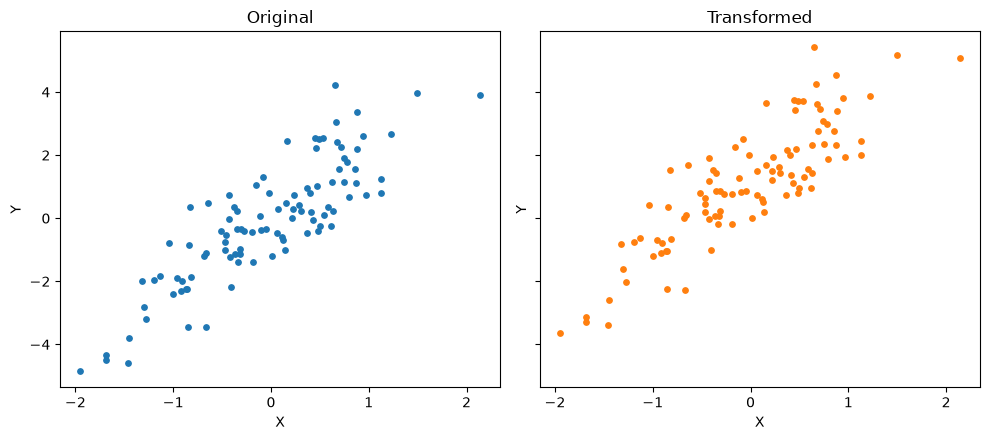

In [22]:
_ = plot_2panel(X, Xt, x_idx=0, y_idx=1, x_name='X', y_name='Y')

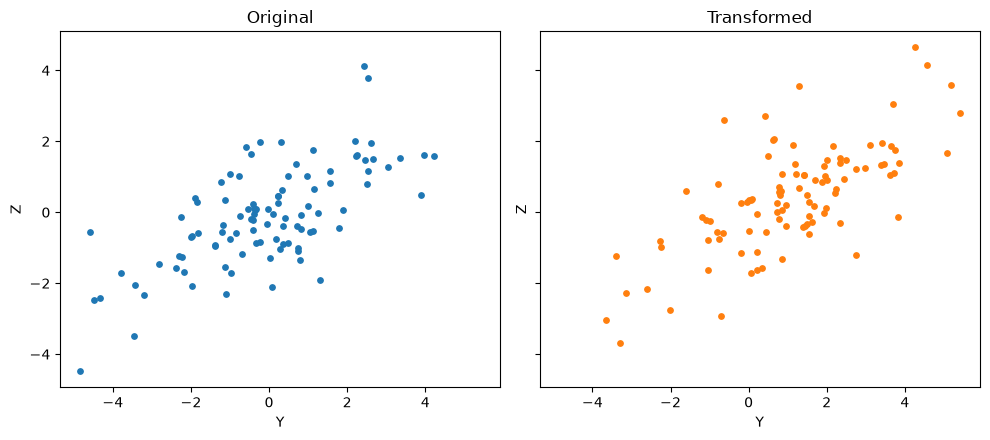

In [23]:
_ = plot_2panel(X, Xt, x_idx=1, y_idx=2, x_name='Y', y_name='Z')

### Propagation to the descendant (Y → Z)

The drift is a single systematic shift, but the propagation is **Pearl surgery with fresh noise**: Z is not translated by a rigid delta — it is **recomputed** from its (shifted) parent through the fitted structural equation, `Z_new = f(Y_shifted) + fresh_noise`. The systematic part of the shift carries through (Z moves because Y moved), but Z's scatter is **re-rolled**, not preserved: the descendant cloud keeps roughly its original width while its position follows the parent's shift. This is what distinguishes drift from noise: drift shifts a node *systematically* (one draw applied to all affected rows), noise scatters it row-by-row — and in both cases the descendants' noise is freshly drawn, never inherited.

## Summary

| Lever | Generator | Uses a DGP? | Propagates? | Deterministic? | Selector support |
|---|---|---|---|---|---|
| observation process | `FixedShiftGenerator` | no | no (values only) | **yes** | — |
| observation process, per class | `FixedShiftClassesGenerator` | no | no (values only) | **yes** | `ClassSelector` |
| observation process | `RandomShiftGenerator` | no | no (values only) | no | — |
| observation process, per class | `RandomShiftClassesGenerator` | no | no (values only) | no | `ClassSelector` |
| DGP | `CausalDriftGenerator` | **yes** (fitted) | **yes** — descendants re-evaluated | no | yes (boolean masks) |

* Drift is a *single* systematic shift per column, applied to all
  affected rows — in contrast to noise, which redraws per row.
* `shift_std` / `drift_std` / `shift` are in units of the column's
  standard deviation (normalize, shift, un-normalize).
* The class column is never shifted by the per-class generators (it
  defines the selection); use `class_column=` / `variables=` to make
  the columns explicit.
* Generators mutate `X` in place — pass `X.copy()` to keep the
  original.

## Takeaways

- Drift translates columns in units of their standard deviation (data are standardized first).
- `FixedShiftGenerator` is deterministic (same input, same output); `RandomShiftGenerator` draws one shift per column with a signed magnitude.
- Per-class drift (`RandomShiftClassesGenerator`) never shifts the class column itself.